In [1]:
import numpy as np
import h2py
import pickle
import matplotlib.pyplot as plt
import matplotlib as mpl
import scipy
import pandas
import demes
import demesdraw

mpl.rc("xtick", labelsize=7)
mpl.rc("ytick", labelsize=7)
mpl.rc("font", size=8)
mpl.rc("axes", labelsize=8)
mpl.rc("axes", titlesize=8)
mpl.rc("legend", fontsize=7)
mpl.rc("axes", titlesize="small")

In [7]:
# Load MLE models
mle_models = {}
mods = ["full_model", "full_model_alt"]
params_files = ["full_model_free_pulse_times_params.yaml", "full_model_alt_params.yaml"]
for rmap in ["bherer", "zhou-JHS"]:
    for mod, params in zip(mods, params_files):
        fnames = []
        lls = []
        for trial in range(30):
            fname = f"fitted_models/main_fit_{mod}_{rmap}_try_{trial}.yaml"
            try:
                g = demes.load(fname)
            except:
                continue
            lls.append(g.metadata["opt_info"]["ll"])
            fnames.append(fname)
        fname = fnames[np.argmax(lls)]
        pvals, pnames = h2py.inference.load_params(fname, params)
        mle_models[(rmap, mod)] = (pvals, pnames)
        print(fname, np.max(lls))

fitted_models/main_fit_full_model_bherer_try_13.yaml -567.0875529020813
fitted_models/main_fit_full_model_alt_bherer_try_22.yaml -577.4491090625145
fitted_models/main_fit_full_model_zhou-JHS_try_0.yaml -570.1874100479539
fitted_models/main_fit_full_model_alt_zhou-JHS_try_16.yaml -580.2149737666193


In [1]:
-567.0875529020813 - -579.4650006685165

12.377447766435239

In [12]:
# Load fitted bootstrap parameters
for rmap in ["bherer", "zhou-JHS"]:
    for mod, params in zip(mods, params_files):
        data = []
        for rep in range(500):
            fname = f"fitted_models/boot_fit_{mod}_{rmap}_rep_{rep}.yaml"
            try:
                pvals, pnames = h2py.inference.load_params(fname, params)
            except:
                continue
            data.append(pvals)
        mle = mle_models[(rmap, mod)][0]
        lower_CI = np.quantile(data, 0.025, axis=0) 
        upper_CI = np.quantile(data, 0.975, axis=0) 
        df = pandas.DataFrame({"name": pnames, "MLE": mle, "CI_lower": lower_CI, "CI_upper": upper_CI})
        df.to_csv(f"bootstrap_{rmap}_{mod}.csv")

In [13]:
df = pandas.read_csv("bootstrap_bherer_full_model.csv")
print(df)

    Unnamed: 0       name            MLE       CI_lower       CI_upper
0            0      T_NDH  778405.999321  742752.125100  839916.138486
1            1       T_ND  668282.043093  618358.684897  736047.677154
2            2      T_AWN  122601.857668  119436.919576  127679.080722
3            3       T_CV   59944.643888   58344.899841   62347.637670
4            4      T_OOA   58481.764527   53577.587414   61388.001903
5            5       T_SL   55866.133547   51003.178816   59288.876867
6            6      T_L_S   31297.530632   17219.868994   35217.008188
7            7     T_MH_N  216270.941399  198939.402197  343059.494414
8            8    T_MH_WN  122601.857667  103785.148121  127240.931733
9            9  T_Vin_OOA   55866.133543   47000.000000   59292.966287
10          10      N_Anc   16782.857238   15821.582056   17478.898424
11          11       N_ND    4571.371480    3499.823880    7043.196643
12          12      N_Den    3478.380696    3046.561333    3657.080715
13    

In [15]:
df = pandas.read_csv("bootstrap_bherer_full_model_alt.csv")
print(df)

    Unnamed: 0       name            MLE       CI_lower       CI_upper
0            0      T_NDH  775653.710358  745614.516077  842583.205272
1            1       T_ND  671610.648248  624513.207817  730314.807264
2            2      T_AWN  122891.646370  119386.050507  126185.628077
3            3       T_CV   60677.258393   58918.260230   62368.515359
4            4      T_OOA   58270.433399   53740.804527   63300.521785
5            5       T_SL   55618.065083   51303.355683   61008.386902
6            6      T_L_S   30867.227912   18233.821098   37193.116689
7            7     T_MH_N  237568.578971  201607.932983  322275.731700
8            8    T_MH_WN  122891.646370  100244.296194  125902.503614
9            9  T_Vin_OOA   47544.024001   45000.000000   53108.840919
10          10      T_Ust   47544.024001   45052.809859   53304.147549
11          11      N_Anc   16846.831671   15682.193346   17315.236852
12          12       N_ND    4445.880285    3820.459184    7069.230417
13    

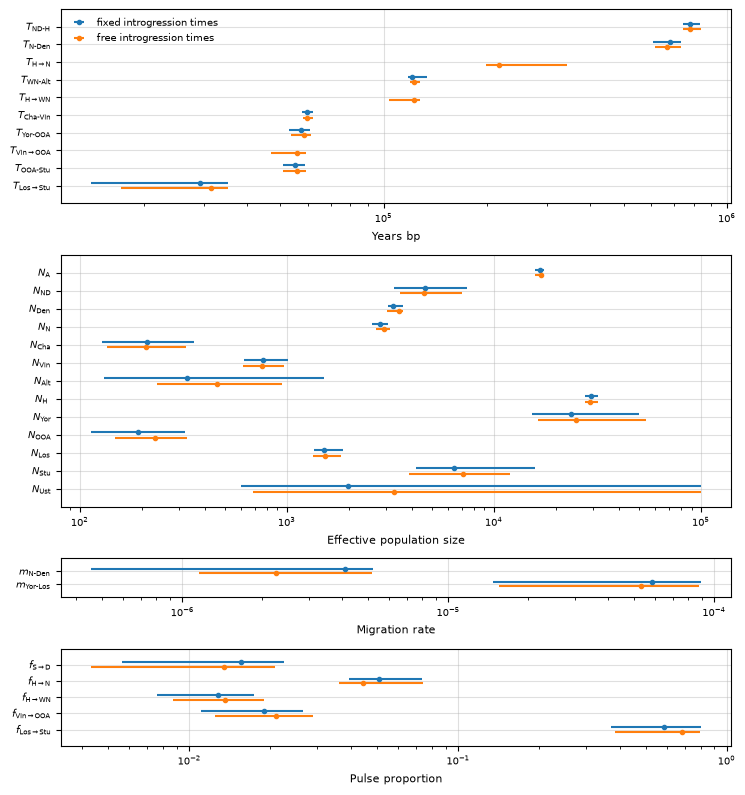

In [2]:
df0 = pandas.read_csv("../mutation_sensitivity/bootstrap_bherer_1.3e-8.csv")
df1 = pandas.read_csv("bootstrap_bherer_full_model.csv")
groups = [
    {"params": ['T_NDH', 'T_ND', "T_MH_N", 'T_AWN', "T_MH_WN", 'T_CV', 'T_OOA', 'T_Vin_OOA', 'T_SL', 'T_L_S'], "log": True},
    {"params": ['N_Anc', 'N_ND', 'N_Den', 'N_N', 'N_Chag', 'N_Vin', 'N_Alt', 'N_MH', 'N_Yor', 'N_OOA', 'N_Los', 'N_Stut', 'N_Ust'],
     "log": True},
    {"params": ["m_ND", "m_LY"], "log": True},
    {"params": ["p_S_D", "p_H_N", "p_H_WN", "p_N_OOA", "p_L_S"], "log": True}
]

x_labels = ["Years bp", "Effective population size", "Migration rate",  "Pulse proportion"]
param_labels = {
    'T_NDH': r'$T_{\text{ND-H}}$',
    'T_ND': r'$T_{\text{N-Den}}$', 
    "T_MH_N": r"$T_{\text{H}\to\text{N}}$",
    'T_AWN': r'$T_{\text{WN-Alt}}$', 
    "T_MH_WN": r"$T_{\text{H}\to\text{WN}}$",
    'T_CV': r'$T_{\text{Cha-Vin}}$', 
    'T_OOA': r'$T_{\text{Yor-OOA}}$', 
    'T_Vin_OOA': r'$T_{\text{Vin}\to\text{OOA}}$', 
    'T_SL': r'$T_{\text{OOA-Stu}}$', 
    'T_L_S': r'$T_{\text{Los}\to\text{Stu}}$', 
    'N_Anc': r'$N_{\text{A}}$',
    "N_S": r"$N_{\text{S}}$ (fixed)",
    'N_ND': r'$N_{\text{ND}}$', 
    'N_N': r'$N_{\text{N}}$', 
    'N_MH': r'$N_{\text{H}}$ ', 
    'N_OOA': r'$N_{\text{OOA}}$',
    'N_Alt': r'$N_{\text{Alt}}$', 
    'N_Chag': r'$N_{\text{Cha}}$', 
    'N_Vin': r'$N_{\text{Vin}}$', 
    'N_Den': r'$N_{\text{Den}}$',
    'N_Los': r'$N_{\text{Los}}$',
    'N_Ust': r'$N_{\text{Ust}}$',
    'N_Stut': r'$N_{\text{Stu}}$',
    'N_Yor': r'$N_{\text{Yor}}$', 
    'm_ND': r'$m_{\text{N-Den}}$', 
    'm_LY': r'$m_{\text{Yor-Los}}$', 
    'p_S_D': r'$f_{\text{S} \to \text{D}}$', 
    'p_H_N': r'$f_{\text{H} \to \text{N}}$',
    'p_H_WN': r'$f_{\text{H} \to \text{WN}}$', 
    'p_N_OOA': r'$f_{\text{Vin}\to\text{OOA}}$', 
    'p_L_S': r'$f_{\text{Los}\to\text{Stu}}$',
}

h2py.plotting.plot_param_distributions(
    [df0, df1],
    groups=groups,
    param_labels=param_labels,
    data_labels=["fixed introgression times", "free introgression times"],
    figsize=(7.5, 8),
    x_labels=x_labels,
    spread=0.15,
    out="../../figures/free_pulse_distrs.pdf"
)

In [22]:
graph = "fitted_models/main_fit_full_model_zhou-JHS_try_0.yaml"
fname = "../bootstrapped_data/accessible_1e-4M_ccds_flank_zhou-JHS_adj.pkl"
with open(fname, "rb") as fin:
    data = pickle.load(fin)
pops = ["Altai", "Vindija", "Chagyrskaya", "Denisova", "Stuttgart", "Loschbour", "UstIshim", "Yoruba1"]
bins = h2py.parsing._get_bin_tuples(np.logspace(-6, -2, 17))
model = h2py.H2stats.from_demes(graph, u=1.3e-8, r_bins=bins, sampled_demes=pops)
data = h2py.parsing.subset_data(data, to_pops=pops)
p1s = [x.split("_")[1] for x in data["stats"][0]]
p2s = [x.split("_")[2] for x in data["stats"][0]]

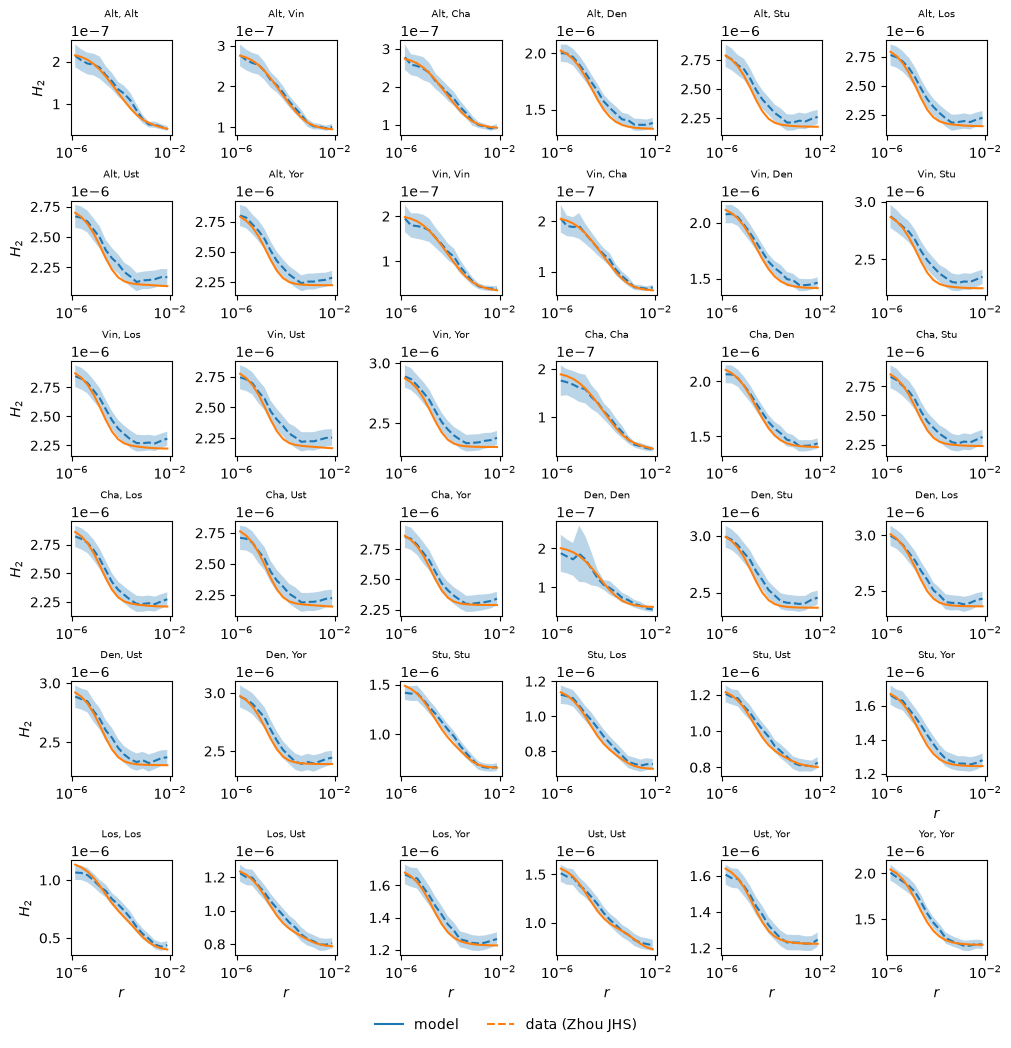

In [23]:
p1s = [int(x.split("_")[1]) for x in data["stats"][0]]
p2s = [int(x.split("_")[2]) for x in data["stats"][0]]
stats = [f"{pops[p1][:3]}, {pops[p2][:3]}" for p1, p2 in zip(p1s, p2s)]

x = h2py.plotting.plot_h2_curves(
    h2_stats=[model],
    means=[data["means"]],
    varcovs=[data["varcovs"]],
    stats=stats,
    fig_size=(10, 10),
    pops=pops,
    rows=6, cols=6,
    r_bins=bins, #data["bins"],
    model_labels=["model"],
    data_labels=["data (Zhou JHS)"],
    out_file="full_model_zhou_curves.pdf"
)

In [24]:
graph = "fitted_models/main_fit_full_model_bherer_try_13.yaml"
fname = "../bootstrapped_data/accessible_1e-4M_ccds_flank_bherer_adj.pkl"
with open(fname, "rb") as fin:
    data = pickle.load(fin)
pops = ["Altai", "Vindija", "Chagyrskaya", "Denisova", "Stuttgart", "Loschbour", "UstIshim", "Yoruba1"]
bins = h2py.parsing._get_bin_tuples(np.logspace(-6, -2, 17))
model = h2py.H2stats.from_demes(graph, u=1.3e-8, r_bins=bins, sampled_demes=pops)
data = h2py.parsing.subset_data(data, to_pops=pops)
p1s = [x.split("_")[1] for x in data["stats"][0]]
p2s = [x.split("_")[2] for x in data["stats"][0]]

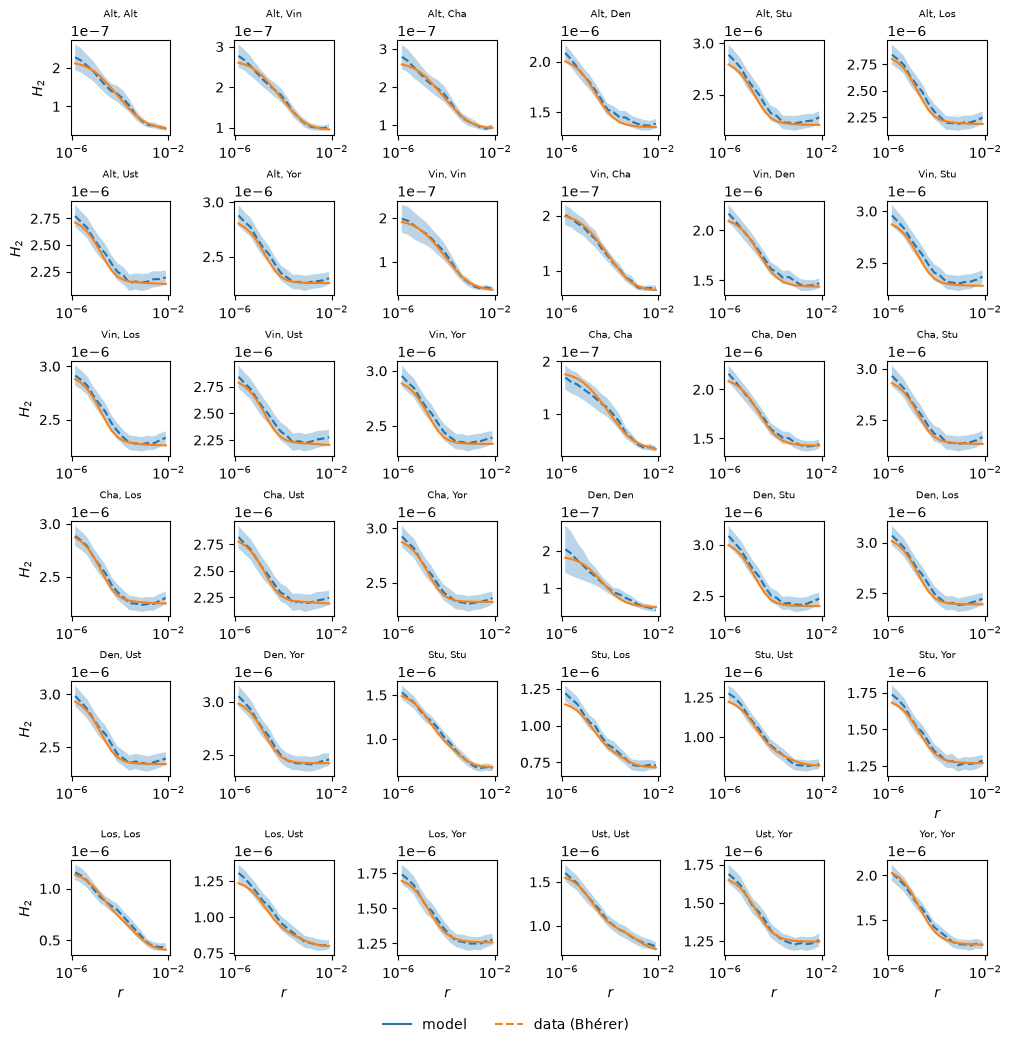

In [25]:
p1s = [int(x.split("_")[1]) for x in data["stats"][0]]
p2s = [int(x.split("_")[2]) for x in data["stats"][0]]
stats = [f"{pops[p1][:3]}, {pops[p2][:3]}" for p1, p2 in zip(p1s, p2s)]

x = h2py.plotting.plot_h2_curves(
    h2_stats=[model],
    means=[data["means"]],
    varcovs=[data["varcovs"]],
    stats=stats,
    fig_size=(10, 10),
    pops=pops,
    rows=6, cols=6,
    r_bins=bins, #data["bins"],
    model_labels=["model"],
    data_labels=["data (Bhérer)"],
    out_file="full_model_bherer_curves.pdf"
)